In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Configuramos el estilo de las gráficas para que se vean profesionales en clase
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. CARGA DE DATOS (California Housing)
california = fetch_california_housing(as_frame=True)

# X: Ingreso medio en el bloque (MedInc - en decenas de miles de dólares)
# Y: Valor medio de la casa (MedHouseVal - en cientos de miles de dólares)
# Tomamos un subconjunto de 50 muestras como indica la guía
X = california.data['MedInc'].values[:50]
Y = california.target.values[:50]

print(f"Datos cargados con éxito: {len(X)} viviendas analizadas.")

Datos cargados con éxito: 50 viviendas analizadas.


In [2]:
# 2. INICIALIZACIÓN DE PARÁMETROS
w = 0.0
b = 0.0

# Hiperparámetros
learning_rate = 0.01  # Tasa de aprendizaje ideal para esta escala
epochs = 1500         # Iteraciones de entrenamiento
n = len(X)
error_threshold = 0.0001 # Umbral de error para detener el entrenamiento si se alcanza

# Historial para graficar la evolución del costo si lo deseas mostrar
historial_costos = []

# 3. ENTRENAMIENTO
for epoch in range(epochs):
    # Predicción actual
    Y_pred = w * X + b
    
    # Cálculo del Costo (MSE)
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)
    
    # Derivadas parciales (Gradientes)
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)
    
    # Actualización de pesos
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Entrenamiento completado!")
print(f"Ecuación final aprendida: Valor Casa = {w:.4f} * (Ingreso Medio) + {b:.4f}")

¡Entrenamiento completado!
Ecuación final aprendida: Valor Casa = 0.4417 * (Ingreso Medio) + 0.6009


In [3]:
historial_costos[-n:]

[np.float64(0.08399267362449334),
 np.float64(0.08399267343466572),
 np.float64(0.08399267324667284),
 np.float64(0.08399267306049697),
 np.float64(0.08399267287612049),
 np.float64(0.08399267269352605),
 np.float64(0.08399267251269638),
 np.float64(0.0839926723336145),
 np.float64(0.08399267215626345),
 np.float64(0.08399267198062653),
 np.float64(0.08399267180668718),
 np.float64(0.08399267163442894),
 np.float64(0.08399267146383563),
 np.float64(0.08399267129489117),
 np.float64(0.08399267112757952),
 np.float64(0.08399267096188498),
 np.float64(0.08399267079779188),
 np.float64(0.08399267063528482),
 np.float64(0.08399267047434837),
 np.float64(0.08399267031496742),
 np.float64(0.08399267015712691),
 np.float64(0.08399267000081194),
 np.float64(0.08399266984600777),
 np.float64(0.08399266969269982),
 np.float64(0.08399266954087362),
 np.float64(0.08399266939051483),
 np.float64(0.0839926692416093),
 np.float64(0.08399266909414296),
 np.float64(0.08399266894810188),
 np.float64(0.08

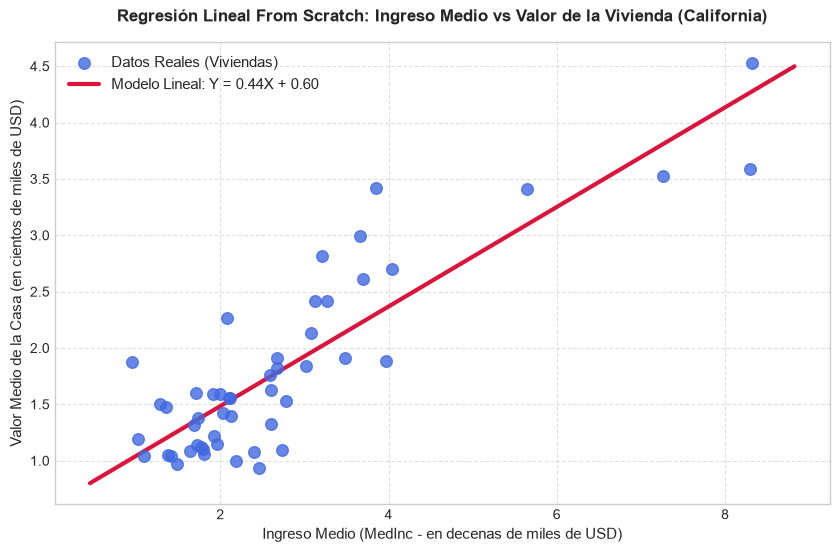

In [4]:
# 4. VISUALIZACIÓN DE RESULTADOS (Recta de Regresión)
plt.figure(figsize=(10, 6))

# Dibujar los puntos reales (Viviendas)
plt.scatter(X, Y, color='royalblue', s=70, alpha=0.8, label='Datos Reales (Viviendas)', zorder=5)

# Dibujar la línea de tendencia aprendida por el modelo
X_linea = np.linspace(min(X) - 0.5, max(X) + 0.5, 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

# Etiquetas y formato estético
plt.title('Regresión Lineal From Scratch: Ingreso Medio vs Valor de la Vivienda (California)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ingreso Medio (MedInc - en decenas de miles de USD)', fontsize=11)
plt.ylabel('Valor Medio de la Casa (en cientos de miles de USD)', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

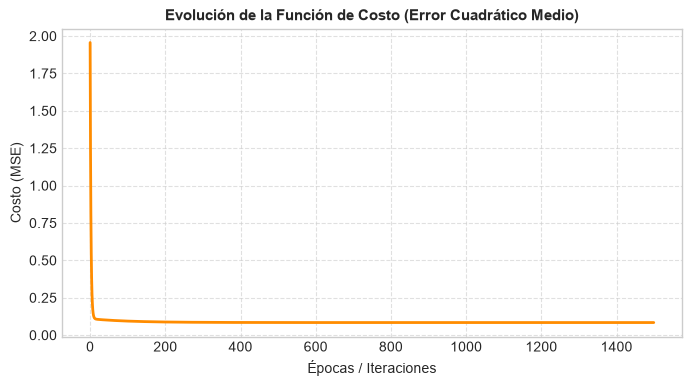

In [5]:
# 5. VISUALIZACIÓN DE LA FUNCIÓN DE COSTO
plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
plt.title('Evolución de la Función de Costo (Error Cuadrático Medio)', fontsize=11, fontweight='bold')
plt.xlabel('Épocas / Iteraciones', fontsize=10)
plt.ylabel('Costo (MSE)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()